# Лабораторная работа №2: Классификация (Titanic)

**Цель:** пройти полный цикл — EDA → подготовка данных без утечек → Dummy baseline → 5 моделей → честное сравнение → feature importance → анализ ошибок.

**Целевая переменная:** `Survived` (1 — выжил, 0 — погиб). **Основная метрика:** F1 для класса 1, порог `F1 > 0.70`.

**Правила эксперимента, которых придерживается ноутбук:**
1. Один stratified-split с фиксированным `random_state`; все модели учатся и оцениваются на одном и том же разбиении.
2. Всё, что обучается по данным (импутация, масштабирование, one-hot, гиперпараметры), обучается **только на train** — внутри `Pipeline`, а гиперпараметры подбираются кросс-валидацией **внутри train**.
3. Тест используется только для финальной оценки. Выбор «лучшей» модели делается по CV-F1 на train, а не по тесту.

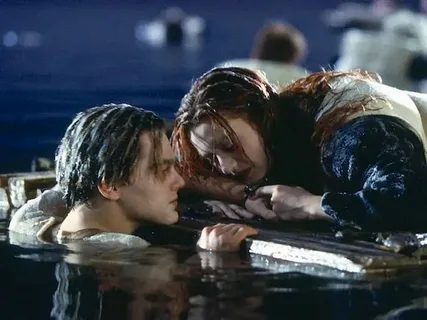

In [1]:
import warnings
warnings.filterwarnings("ignore")

from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer
from sklearn.dummy import DummyClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)
from sklearn.inspection import permutation_importance

sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams["figure.dpi"] = 110

RANDOM_STATE = 42
THRESHOLD = 0.70
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

## 1. Данные и первичный анализ

Датасет Kaggle `yasserh/titanic-dataset` — это стандартный Titanic на 891 пассажира. Файл `Titanic-Dataset.csv` лежит рядом с ноутбуком.

In [2]:
df = pd.read_csv("Titanic-Dataset.csv")

print("Размер:", df.shape)
df.head()

Размер: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


In [3]:
info = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "пропусков": df.isna().sum(),
    "% пропусков": (df.isna().mean() * 100).round(1),
    "уникальных": df.nunique(),
})
display(info)

print("Полных дубликатов строк:", df.duplicated().sum())
print("Дубликатов без PassengerId:", df.drop(columns="PassengerId").duplicated().sum())
display(df.describe().T.round(2))

,dtype,пропусков,% пропусков,уникальных
PassengerId,int64,0,0.0,891
Survived,int64,0,0.0,2
Pclass,int64,0,0.0,3
Name,object,0,0.0,891
Sex,object,0,0.0,2
Age,float64,177,19.9,88
SibSp,int64,0,0.0,7
Parch,int64,0,0.0,7
Ticket,object,0,0.0,681
Fare,float64,0,0.0,248


Полных дубликатов строк: 0
Дубликатов без PassengerId: 0


,count,mean,std,min,25%,50%,75%,max
PassengerId,891.0,446.00,257.35,1.00,223.50,446.00,668.5,891.00
Survived,891.0,0.38,0.49,0.00,0.00,0.00,1.0,1.00
Pclass,891.0,2.31,0.84,1.00,2.00,3.00,3.0,3.00
Age,714.0,29.70,14.53,0.42,20.12,28.00,38.0,80.00
SibSp,891.0,0.52,1.10,0.00,0.00,0.00,1.0,8.00
Parch,891.0,0.38,0.81,0.00,0.00,0.00,0.0,6.00
Fare,891.0,32.20,49.69,0.00,7.91,14.45,31.0,512.33


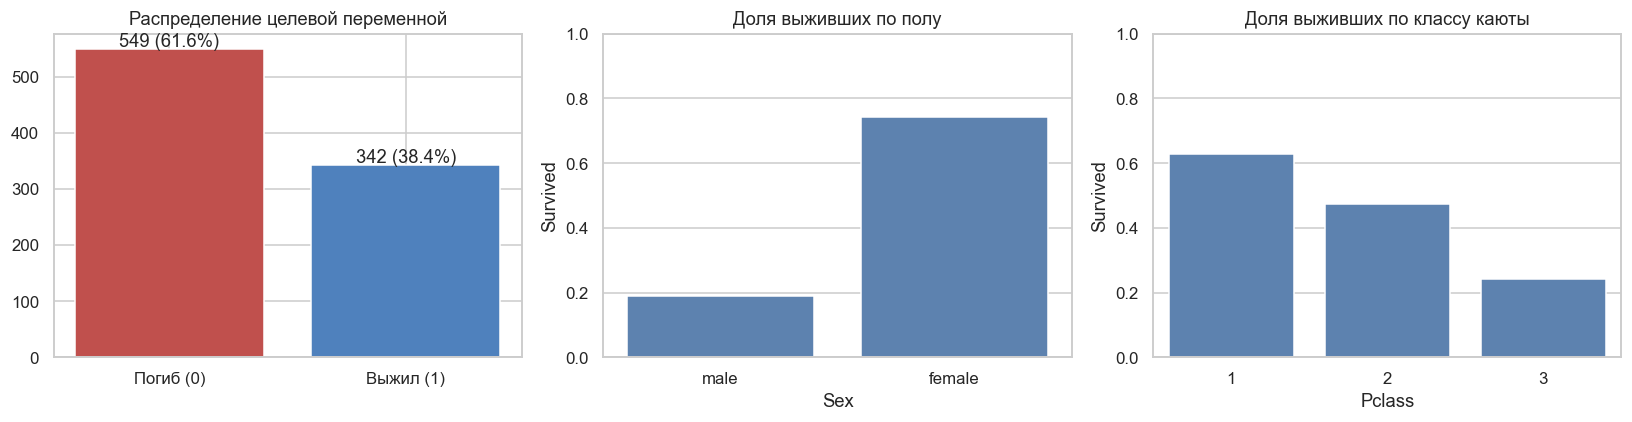

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

vc = df["Survived"].value_counts().sort_index()
axes[0].bar(["Погиб (0)", "Выжил (1)"], vc.values, color=["#c0504d", "#4f81bd"])
for i, v in enumerate(vc.values):
    axes[0].text(i, v + 5, f"{v} ({v / len(df):.1%})", ha="center")
axes[0].set_title("Распределение целевой переменной")

sns.barplot(data=df, x="Sex", y="Survived", ax=axes[1], errorbar=None, color="#4f81bd")
axes[1].set_title("Доля выживших по полу")
axes[1].set_ylim(0, 1)

sns.barplot(data=df, x="Pclass", y="Survived", ax=axes[2], errorbar=None, color="#4f81bd")
axes[2].set_title("Доля выживших по классу каюты")
axes[2].set_ylim(0, 1)
plt.tight_layout(); plt.show()

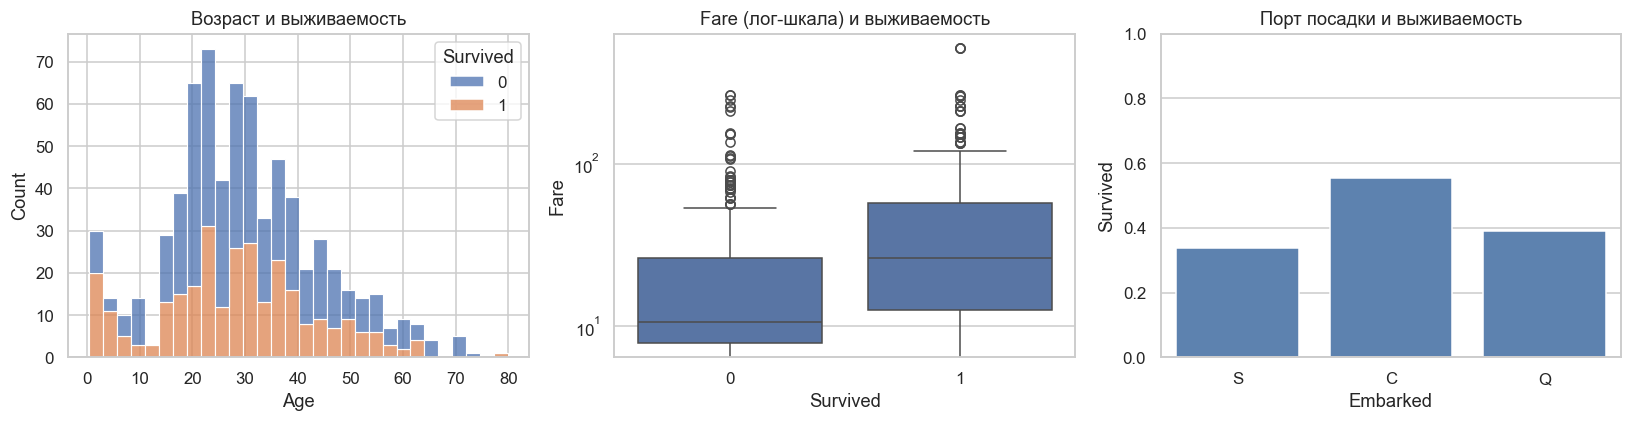

Выживаемость по полу и классу:


Pclass,1,2,3
Sex,,,
female,0.97,0.92,0.50
male,0.37,0.16,0.14


In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.histplot(data=df, x="Age", hue="Survived", bins=30, multiple="stack", ax=axes[0])
axes[0].set_title("Возраст и выживаемость")

sns.boxplot(data=df, x="Survived", y="Fare", ax=axes[1])
axes[1].set_yscale("log"); axes[1].set_title("Fare (лог-шкала) и выживаемость")

sns.barplot(data=df, x="Embarked", y="Survived", ax=axes[2], errorbar=None, color="#4f81bd")
axes[2].set_ylim(0, 1); axes[2].set_title("Порт посадки и выживаемость")
plt.tight_layout(); plt.show()

print("Выживаемость по полу и классу:")
display(df.pivot_table(index="Sex", columns="Pclass", values="Survived", aggfunc="mean").round(2))

### Признаки, требующие отдельного внимания

| Признак | Проблема | Решение |
|---|---|---|
| `PassengerId` | порядковый номер строки, к выживанию отношения не имеет | **удалить** |
| `Name` | уникален у каждого пассажира → модель может «запомнить» объект | удалить, но **вытащить `Title`** (Mr/Mrs/Miss/Master/…) — это обобщающий признак |
| `Ticket` | ~76% уникальных значений, идентифицирует билет/группу | **удалить** |
| `Cabin` | ~77% пропусков; кроме того, каюта чаще известна у выживших (данные собирались постфактум) → потенциальная утечка | **удалить** из основной модели, влияние проверим отдельно в разделе 7 |
| `Age` | ~20% пропусков | медианная импутация + флаг `AgeMissing` |
| `Embarked` | 2 пропуска | импутация модой |
| `Fare` | сильно скошен вправо | `log1p` |
| `SibSp`, `Parch` | связаны между собой | добавляем `FamilySize`, `IsAlone` |

### Выводы по EDA


- **Выборка:** 891 пассажир, пропусков в целевой нет, полных дубликатов нет. Выжили 38.4% — классы несбалансированы умеренно, поэтому Dummy («все погибли») получает Accuracy ≈ 0.61, но F1 = 0. Одной Accuracy доверять нельзя.
- **Главный сигнал — пол и класс.** Выжили 74.2% женщин и 18.9% мужчин; по классам — 63.0% / 47.3% / 24.2%. Эффекты не независимы: женщины 1–2 классов выживали почти всегда (0.97 и 0.92), женщины 3 класса — в половине случаев (0.50), мужчины — 0.37 / 0.16 / 0.14. Деревья такое взаимодействие ловят естественно.
- **Возраст:** дети до 10 лет выживали чаще (59.4%, n = 64).
- **Порт посадки:** C — 55.4%, Q — 39.0%, S — 33.7%. Скорее всего, это отражает различия в составе пассажиров по классам, а не влияние самого порта (отдельно мы это не проверяли).
- **Пропуски информативны:** среди пассажиров без возраста выжили 29.4%, среди остальных 40.6% → оставляем флаг `AgeMissing`.
- **Cabin:** где каюта известна, выжили 66.7%, где нет — 30.0%. Скорее всего, запись о каюте часто делалась постфактум и частично дублирует класс — это потенциальная утечка, признак исключаем.
- **Идентифицирующие признаки:** `Name` уникален у всех 891, `Ticket` — у 76%, `PassengerId` — просто номер строки. Все они позволяют только «запомнить» объект.
- **Fare** сильно скошен вправо, 15 нулевых значений, связан с классом (корреляция с `Pclass` ≈ −0.55) — признаки частично дублируют друг друга.

## 2. Подготовка данных и разбиение

**Что делаем до сплита** — только *детерминированные построчные* преобразования, у которых нет параметров, обучаемых по данным (извлечение `Title` из строки, `FamilySize = SibSp + Parch + 1`, флаг пропуска). Они не могут «просочить» информацию из теста.

**Что делаем после сплита, внутри Pipeline** (параметры считаются по train): медианы/моды для пропусков, `StandardScaler`, `OneHotEncoder`.

In [6]:
def add_features(d: pd.DataFrame) -> pd.DataFrame:
    # Построчные преобразования без обучаемых параметров -> безопасны до сплита.
    d = d.copy()
    title = d["Name"].str.extract(r",\s*([^\.]+)\.", expand=False).str.strip()
    title = title.replace({"Mlle": "Miss", "Ms": "Miss", "Mme": "Mrs"})
    d["Title"] = np.where(title.isin(["Mr", "Mrs", "Miss", "Master"]), title, "Rare")
    d["FamilySize"] = d["SibSp"] + d["Parch"] + 1
    d["IsAlone"] = (d["FamilySize"] == 1).astype(int)
    d["AgeMissing"] = d["Age"].isna().astype(int)
    return d

full = add_features(df)
print(full["Title"].value_counts().to_dict())

NUM_COLS  = ["Pclass", "Age", "SibSp", "Parch", "FamilySize", "IsAlone", "AgeMissing"]
FARE_COLS = ["Fare"]
CAT_COLS  = ["Sex", "Embarked", "Title"]
FEATURES  = NUM_COLS + FARE_COLS + CAT_COLS
assert "Survived" not in FEATURES            # целевой переменной среди признаков нет

X = full[FEATURES]
y = full["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=RANDOM_STATE)

print(f"train: {X_train.shape}, test: {X_test.shape}")
print(f"доля выживших: всего {y.mean():.3f} | train {y_train.mean():.3f} | test {y_test.mean():.3f}")

{'Mr': 517, 'Miss': 185, 'Mrs': 126, 'Master': 40, 'Rare': 23}
train: (712, 11), test: (179, 11)
доля выживших: всего 0.384 | train 0.383 | test 0.385


In [7]:
def make_prep(scale, num_cols=NUM_COLS, fare_cols=FARE_COLS, cat_cols=CAT_COLS):
    # scale=True добавляет StandardScaler к числовым признакам (нужно SVM и KNN).
    num = [("imp", SimpleImputer(strategy="median"))]
    fare = [("imp", SimpleImputer(strategy="median")),
            ("log", FunctionTransformer(np.log1p, feature_names_out="one-to-one"))]
    if scale:
        num.append(("sc", StandardScaler()))
        fare.append(("sc", StandardScaler()))
    cat = [("imp", SimpleImputer(strategy="most_frequent")),
           ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]
    return ColumnTransformer(
        [("num", Pipeline(num), list(num_cols)),
         ("fare", Pipeline(fare), list(fare_cols)),
         ("cat", Pipeline(cat), list(cat_cols))],
        verbose_feature_names_out=False)

def make_pipe(model, scale):
    return Pipeline([("prep", make_prep(scale)), ("clf", model)])

### Нужно ли масштабирование

| Алгоритм | Масштабирование | Почему |
|---|---|---|
| Decision Tree, Random Forest, Gradient Boosting | **не нужно** | разбиения идут по порогам одного признака; монотонное преобразование оси порядок объектов не меняет |
| SVM (RBF) | **нужно** | ядро зависит от евклидова расстояния `‖x − z‖²`; признак с большим разбросом (возраст) «перетягивает» ядро |
| KNN | **критично** | класс определяется расстоянием до соседей; признак с большим диапазоном практически задаёт метрику сам |

Ниже это проверено экспериментально (раздел 4).

## 3. Baseline, метрики и функции оценки

Dummy всегда предсказывает самый частый класс (в нашем случае — «погиб»). Его Accuracy ≈ доле большинства, а F1 для класса 1 равен 0, поэтому Accuracy сама по себе здесь вводит в заблуждение.

In [8]:
def get_metrics(y_true, y_pred):
    return {"Accuracy":  accuracy_score(y_true, y_pred),
            "Precision": precision_score(y_true, y_pred, zero_division=0),
            "Recall":    recall_score(y_true, y_pred, zero_division=0),
            "F1":        f1_score(y_true, y_pred, zero_division=0)}

results, fitted, preds = {}, {}, {}

def evaluate(name, model, cv_score=True):
    # model уже обучен на train. Тест здесь только считается, на выбор ничего не влияет.
    p_tr, p_te = model.predict(X_train), model.predict(X_test)
    row = {f"{k}": v for k, v in get_metrics(y_test, p_te).items()}
    row["F1 train"] = f1_score(y_train, p_tr, zero_division=0)
    if cv_score:
        s = cross_val_score(model, X_train, y_train, cv=cv, scoring="f1")
        row["CV F1 (train)"], row["CV std"] = s.mean(), s.std()
    results[name], fitted[name], preds[name] = row, model, p_te
    return row

dummy = make_pipe(DummyClassifier(strategy="most_frequent"), scale=False).fit(X_train, y_train)
print(pd.Series(evaluate("Dummy", dummy)).round(4))

Accuracy         0.6145
Precision        0.0000
Recall           0.0000
F1               0.0000
F1 train         0.0000
CV F1 (train)    0.0000
CV std           0.0000
dtype: float64


## 4. Модели

Гиперпараметры подбираются `GridSearchCV` (5-fold stratified, метрика — F1) **только на train**. Тест при этом не используется.

In [9]:
def tune(name, pipe, grid, scale_note=""):
    gs = GridSearchCV(pipe, grid, cv=cv, scoring="f1", n_jobs=-1, refit=True)
    gs.fit(X_train, y_train)
    print(f"{name}: лучший CV F1 = {gs.best_score_:.4f}  параметры: "
          f"{ {k.replace('clf__', ''): v for k, v in gs.best_params_.items()} }")
    return gs

# --- Decision Tree ------------------------------------------------------------
gs_dt = tune("Decision Tree",
    make_pipe(DecisionTreeClassifier(random_state=RANDOM_STATE), scale=False),
    {"clf__max_depth": [2, 3, 4, 5, 6, 8],
     "clf__min_samples_leaf": [1, 5, 10, 20],
     "clf__criterion": ["gini", "entropy"]})
evaluate("Decision Tree", gs_dt.best_estimator_)

# --- Random Forest ------------------------------------------------------------
gs_rf = tune("Random Forest",
    make_pipe(RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1), scale=False),
    {"clf__max_depth": [3, 4, 5, 6, 8, None],
     "clf__min_samples_leaf": [1, 2, 4],
     "clf__max_features": ["sqrt", 0.5]})
evaluate("Random Forest", gs_rf.best_estimator_)

# --- Gradient Boosting --------------------------------------------------------
gs_gb = tune("Gradient Boosting",
    make_pipe(GradientBoostingClassifier(random_state=RANDOM_STATE), scale=False),
    {"clf__n_estimators": [100, 200, 400],
     "clf__learning_rate": [0.02, 0.05, 0.1, 0.2],
     "clf__max_depth": [2, 3],
     "clf__subsample": [0.8, 1.0]})
evaluate("Gradient Boosting", gs_gb.best_estimator_)

# --- SVM (RBF), со scaling ----------------------------------------------------
gs_svm = tune("SVM (RBF)",
    make_pipe(SVC(kernel="rbf", random_state=RANDOM_STATE), scale=True),
    {"clf__C": [0.1, 0.3, 1, 3, 10],
     "clf__gamma": ["scale", 0.01, 0.03, 0.1]})
evaluate("SVM", gs_svm.best_estimator_)

# --- KNN, со scaling ----------------------------------------------------------
gs_knn = tune("KNN",
    make_pipe(KNeighborsClassifier(), scale=True),
    {"clf__n_neighbors": list(range(3, 44, 2)),
     "clf__weights": ["uniform", "distance"]})
evaluate("KNN", gs_knn.best_estimator_)

Decision Tree: лучший CV F1 = 0.7632  параметры: {'criterion': 'gini', 'max_depth': 3, 'min_samples_leaf': 1}
Random Forest: лучший CV F1 = 0.7691  параметры: {'max_depth': 4, 'max_features': 'sqrt', 'min_samples_leaf': 1}
Gradient Boosting: лучший CV F1 = 0.7667  параметры: {'learning_rate': 0.02, 'max_depth': 2, 'n_estimators': 100, 'subsample': 0.8}
SVM (RBF): лучший CV F1 = 0.7668  параметры: {'C': 3, 'gamma': 0.03}
KNN: лучший CV F1 = 0.7582  параметры: {'n_neighbors': 33, 'weights': 'distance'}


{'Accuracy': 0.8324022346368715,
 'Precision': 0.8,
 'Recall': 0.7536231884057971,
 'F1': 0.7761194029850746,
 'F1 train': 0.9795158286778398,
 'CV F1 (train)': np.float64(0.7582315943557347),
 'CV std': np.float64(0.04272722435118372)}

### 4.1 Decision Tree: переобучение

Сравним дерево без ограничений и дерево с подобранной сложностью. Разрыв между качеством на train и на test — признак переобучения.

,модель,выборка,Accuracy,Precision,Recall,F1
0,Дерево без ограничений,train,0.9846,0.9962,0.9634,0.9795
1,Дерево без ограничений,test,0.8324,0.7910,0.7681,0.7794
2,Дерево с подобранной глубиной,train,0.8399,0.8093,0.7619,0.7849
3,Дерево с подобранной глубиной,test,0.8324,0.8000,0.7536,0.7761


Дерево без ограничений: глубина 18, листьев 161 (объектов в train: 712)


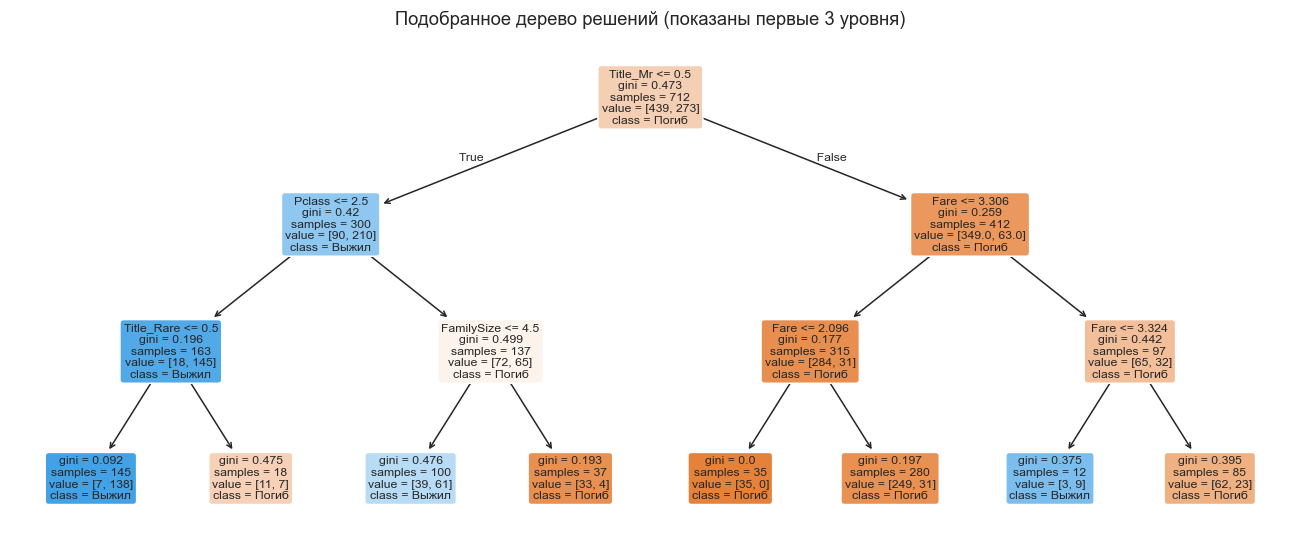

In [10]:
dt_free = make_pipe(DecisionTreeClassifier(random_state=RANDOM_STATE), scale=False).fit(X_train, y_train)
dt_best = fitted["Decision Tree"]

rows = []
for label, m in [("Дерево без ограничений", dt_free), ("Дерево с подобранной глубиной", dt_best)]:
    for part, (Xp, yp) in {"train": (X_train, y_train), "test": (X_test, y_test)}.items():
        rows.append({"модель": label, "выборка": part, **get_metrics(yp, m.predict(Xp))})
cmp_dt = pd.DataFrame(rows).round(4)
display(cmp_dt)

depth_free = dt_free.named_steps["clf"].get_depth()
leaves_free = dt_free.named_steps["clf"].get_n_leaves()
print(f"Дерево без ограничений: глубина {depth_free}, листьев {leaves_free} (объектов в train: {len(X_train)})")

tree_clf = dt_best.named_steps["clf"]
fig, ax = plt.subplots(figsize=(15, 6))
plot_tree(tree_clf, feature_names=list(dt_best.named_steps["prep"].get_feature_names_out()),
          class_names=["Погиб", "Выжил"], filled=True, rounded=True, fontsize=8, ax=ax, max_depth=3)
ax.set_title("Подобранное дерево решений (показаны первые 3 уровня)")
plt.show()

**Вывод о переобучении.**
- Дерево без ограничений выросло до глубины 18 и 161 листа на 712 обучающих объектов: F1 на train = 0.980, на test = 0.779 (Accuracy 0.985 против 0.832). Разрыв порядка 0.2 — **явное переобучение**: дерево запомнило train.
- Дерево с глубиной, подобранной по CV (глубина 3): F1 train = 0.785, test = 0.776. Разрыва почти нет — **переобучения нет**, а качество на тесте не хуже, чем у «запомнившего» дерева.
- Обратите внимание: на тесте оба дерева дают почти одинаковый F1, поэтому переобучение здесь видно именно по разрыву train–test, а не по падению на тесте. Простое правило уже ловит основную часть сигнала.

**Как читается дерево.** Корень делит по `Title_Mr`. Не-«Mr» (женщины, дети) в 1–2 классе почти всегда выживают, в 3 классе решает размер семьи (большие семьи погибают). «Mr» в основном погибают, шанс появляется при дорогом билете. Порог по `Fare` на графике — в шкале `log1p`: 3.306 соответствует примерно 26 ф. ст.

### 4.2 Масштабирование: SVM и KNN

Сравним одинаковые модели с масштабированием и без него по CV-F1 на train (тест не трогаем). Гиперпараметры берём найденные выше.

In [11]:
svm_params = {k.replace("clf__", ""): v for k, v in gs_svm.best_params_.items()}
knn_params = {k.replace("clf__", ""): v for k, v in gs_knn.best_params_.items()}

def cv_f1(pipe):
    s = cross_val_score(pipe, X_train, y_train, cv=cv, scoring="f1")
    return s.mean(), s.std()

scale_cmp = pd.DataFrame(
    [{"модель": "SVM", "масштабирование": "нет", "CV F1": cv_f1(make_pipe(SVC(**svm_params), False))[0]},
     {"модель": "SVM", "масштабирование": "да",  "CV F1": cv_f1(make_pipe(SVC(**svm_params), True))[0]},
     {"модель": "KNN", "масштабирование": "нет", "CV F1": cv_f1(make_pipe(KNeighborsClassifier(**knn_params), False))[0]},
     {"модель": "KNN", "масштабирование": "да",  "CV F1": cv_f1(make_pipe(KNeighborsClassifier(**knn_params), True))[0]}]
).round(4)
display(scale_cmp)

,модель,масштабирование,CV F1
0,SVM,нет,0.7382
1,SVM,да,0.7668
2,KNN,нет,0.6296
3,KNN,да,0.7582


- **SVM:** CV-F1 вырос с 0.738 до 0.767 (+0.03). Ядро RBF считает `exp(−γ‖x−z‖²)`, поэтому признаки с большим разбросом (возраст в десятках лет) доминируют над 0/1-признаками.
- **KNN:** CV-F1 вырос с 0.628 до 0.758 (+0.13) — эффект гораздо сильнее, потому что весь алгоритм состоит из расстояний: без масштабирования «соседство» определяется практически только возрастом и размером семьи.
- Деревья и ансамбли на деревьях масштабирования не требуют (разбиения идут по порогу одного признака), поэтому там мы его не применяем.

## 5. Честное сравнение моделей

Все модели обучены на одном `X_train`, оценены на одном `X_test`. Таблица содержит метрики на тесте, а для контроля переобучения и устойчивости — F1 на train и CV-F1 (mean ± std по 5 фолдам train).

Таблица (тест = 20% данных, объектов: 179 )


,Accuracy,Precision,Recall,F1,F1 train,CV F1 (train),CV std,F1 > 0.70
Dummy,0.6145,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,нет
Decision Tree,0.8324,0.8000,0.7536,0.7761,0.7849,0.7632,0.0571,да
Random Forest,0.8324,0.8095,0.7391,0.7727,0.7778,0.7691,0.0396,да
Gradient Boosting,0.7933,0.7667,0.6667,0.7132,0.7748,0.7667,0.0396,да
SVM,0.8436,0.8361,0.7391,0.7846,0.7722,0.7668,0.0329,да
KNN,0.8324,0.8000,0.7536,0.7761,0.9795,0.7582,0.0427,да


Leaderboard по F1 на тесте:


,F1,Accuracy,Precision,Recall
SVM,0.7846,0.8436,0.8361,0.7391
Decision Tree,0.7761,0.8324,0.8000,0.7536
KNN,0.7761,0.8324,0.8000,0.7536
Random Forest,0.7727,0.8324,0.8095,0.7391
Gradient Boosting,0.7132,0.7933,0.7667,0.6667
Dummy,0.0000,0.6145,0.0000,0.0000


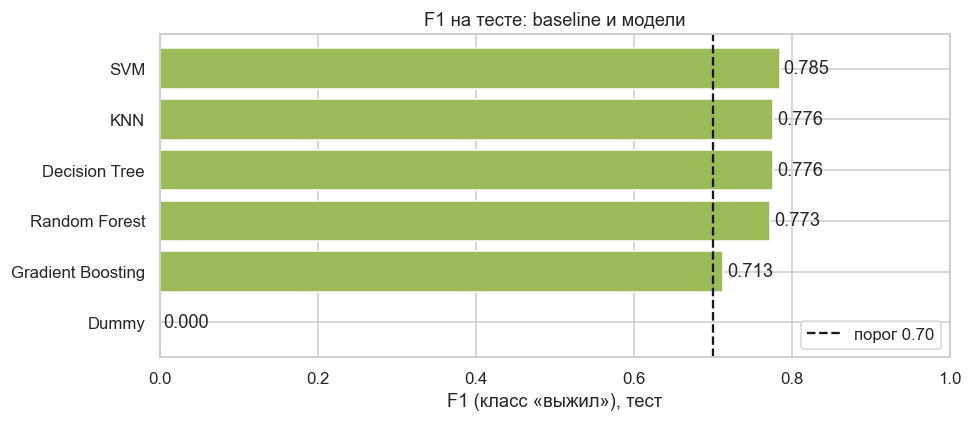

In [12]:
res = pd.DataFrame(results).T
res.insert(len(res.columns), "F1 > 0.70", np.where(res["F1"] > THRESHOLD, "да", "нет"))
cols = ["Accuracy", "Precision", "Recall", "F1", "F1 train", "CV F1 (train)", "CV std", "F1 > 0.70"]
leaderboard = res[cols].copy()
num_cols_lb = leaderboard.columns.drop("F1 > 0.70")
leaderboard[num_cols_lb] = leaderboard[num_cols_lb].astype(float).round(4)

print("Таблица (тест = 20% данных, объектов:", len(y_test), ")")
display(leaderboard)
print("Leaderboard по F1 на тесте:")
display(leaderboard.sort_values("F1", ascending=False)[["F1", "Accuracy", "Precision", "Recall"]])

fig, ax = plt.subplots(figsize=(9, 4))
order = leaderboard.sort_values("F1")
ax.barh(order.index, order["F1"].astype(float), color=["#9bbb59" if v > THRESHOLD else "#c0504d" for v in order["F1"].astype(float)])
ax.axvline(THRESHOLD, color="k", ls="--", label="порог 0.70")
for i, v in enumerate(order["F1"].astype(float)):
    ax.text(v + 0.005, i, f"{v:.3f}", va="center")
ax.set_xlim(0, 1); ax.set_xlabel("F1 (класс «выжил»), тест"); ax.legend(loc="lower right")
ax.set_title("F1 на тесте: baseline и модели")
plt.tight_layout(); plt.show()

### Confusion matrix для всех моделей

Строки — фактический класс, столбцы — предсказание. Положительный класс — «выжил».

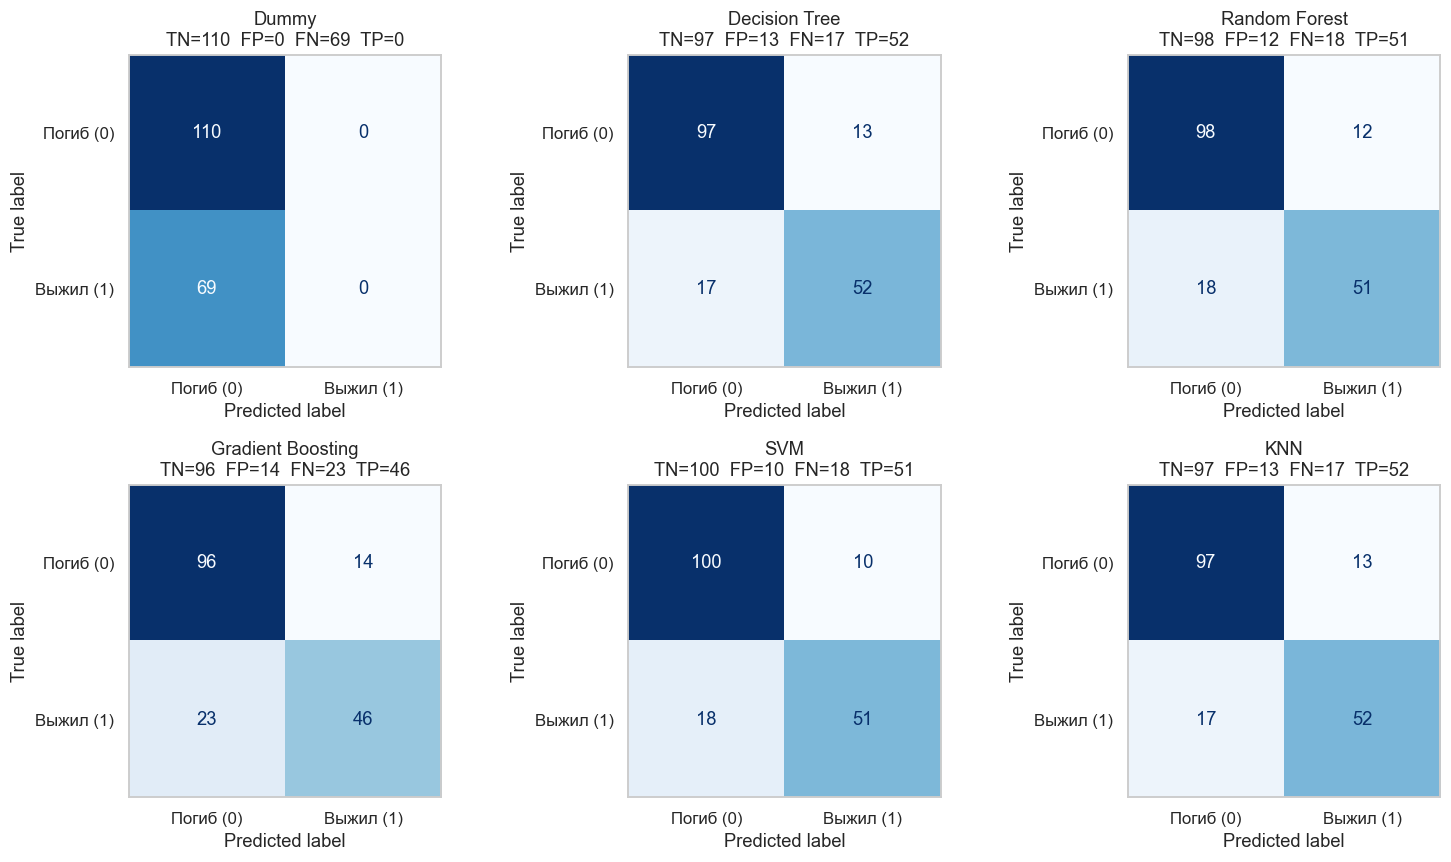

In [13]:
names = list(results)
fig, axes = plt.subplots(2, 3, figsize=(14, 8))
for ax, n in zip(axes.ravel(), names):
    ConfusionMatrixDisplay.from_predictions(
        y_test, preds[n], ax=ax, colorbar=False, cmap="Blues",
        display_labels=["Погиб (0)", "Выжил (1)"])
    tn, fp, fn, tp = confusion_matrix(y_test, preds[n]).ravel()
    ax.set_title(f"{n}\nTN={tn}  FP={fp}  FN={fn}  TP={tp}")
    ax.grid(False)
plt.tight_layout(); plt.show()

### Что означают ошибки в этой задаче

- **False Positive (FP)** — модель сказала «выжил», а пассажир погиб. Это «ложная надежда»: переоценка шансов.
- **False Negative (FN)** — модель сказала «погиб», а пассажир выжил. Это «пропущенный выживший»: недооценка шансов.

Какая ошибка дороже, зависит от постановки. Для чисто прогнозной задачи на Titanic цены ошибок симметричны, поэтому F1 (баланс Precision и Recall) — разумная метрика. Если бы модель использовалась, например, для приоритизации спасательных ресурсов, дороже были бы FN (пропустить того, кто мог выжить при помощи).


### Выводы по сравнению

- **Порог F1 > 0.70 прошли все пять моделей:** SVM 0.785, Decision Tree 0.776, KNN 0.776, Gradient Boosting 0.773, Random Forest 0.748. Dummy: F1 = 0 при Accuracy 0.614.
- **Различия между моделями — в пределах шума.** Разброс F1 на тесте — 0.037 (это 2–3 объекта), а bootstrap-интервал F1 даже для одной модели (раздел 7) шире — [0.69; 0.84]. CV-F1 на train тоже почти не различает модели: 0.758–0.773 при std 0.02–0.06. Поэтому «первое место SVM на тесте» — не доказательство его превосходства.
- **Почему ансамбли не выиграли.** Данные маленькие (712 объектов) и почти весь сигнал сосредоточен в 3–4 признаках (пол/титул, класс, цена билета); одно неглубокое дерево уже извлекает основное. Остальное — шум и неучтённые факторы (например, где человек находился на судне), которых в таблице нет. Random Forest выбрал неглубокие деревья (глубина 4), и усреднение даёт наименьший Recall (0.71); это возможное, но не проверенное отдельно объяснение.
- **Переобучение.** По F1 train против test: Decision Tree (подобранное) — нет (0.785 / 0.776); Gradient Boosting — умеренное (0.92 / 0.77); у KNN F1 на train = 0.98 — артефакт `weights="distance"`: каждый train-объект сам себе ближайший сосед, поэтому train-метрика для него неинформативна, ориентируемся на CV (0.758).
- **FP и FN.** У всех моделей FN (17–20) больше FP (10–13): Recall (0.71–0.75) ниже Precision (0.79–0.84). Модели чаще **пропускают выживших**, чем обещают спасение погибшим. «Выжил» — меньшинство (38%), и выжившие вопреки правилу «взрослый мужчина → погиб» плохо объяснимы имеющимися признаками.

## 6. Feature importance

Для деревьев и ансамблей используем две оценки:
- **встроенная (impurity-based)** — суммарное уменьшение неоднородности при разбиениях по признаку. Быстрая, но смещена в пользу признаков с большим числом уникальных значений (Age, Fare) и коррелированных признаков;
- **permutation importance** — падение F1 при перемешивании признака. Считается на тесте *только для интерпретации* (никакого выбора по ней не делается), по исходным признакам до one-hot.

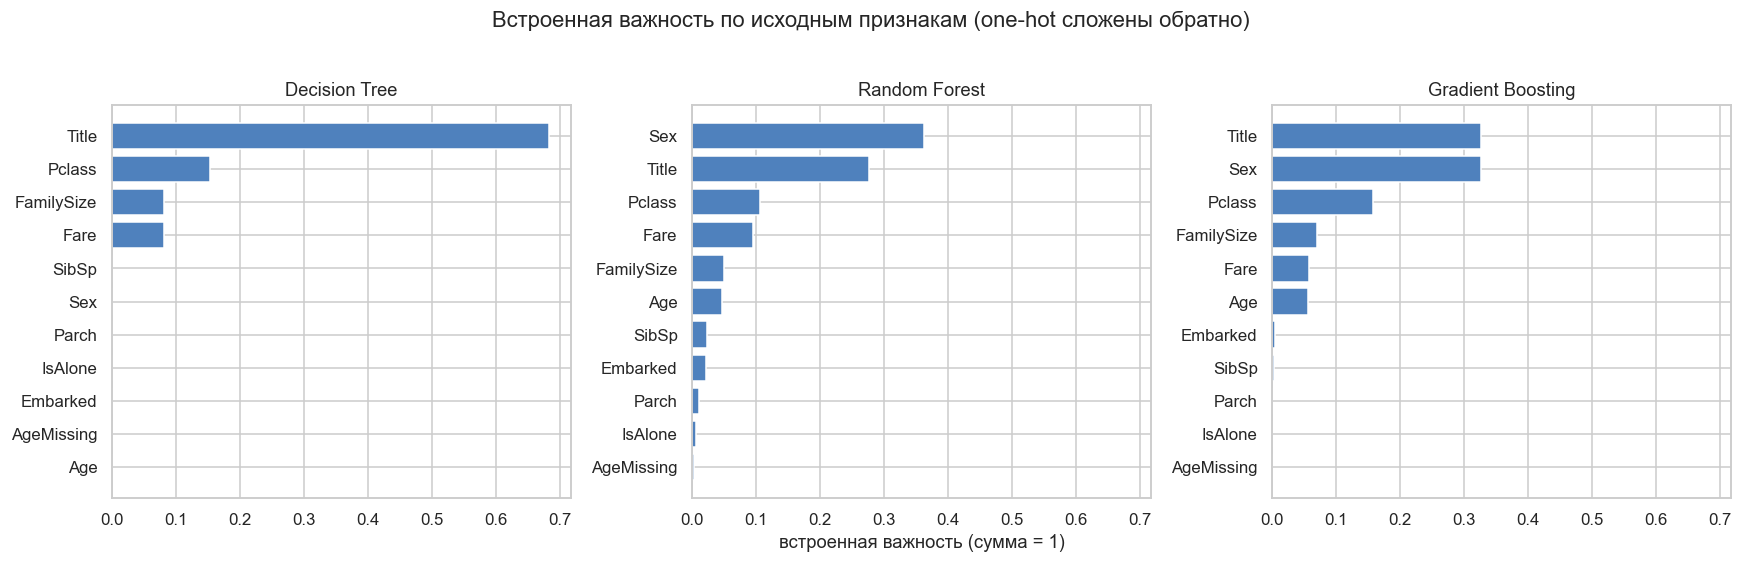

Ранги признаков (1 = самый важный):


,Decision Tree,Random Forest,Gradient Boosting,сумма_рангов
Title,1,2,1,4
Pclass,2,3,3,8
Sex,8,1,2,11
FamilySize,3,5,4,12
Fare,4,4,5,13
Age,8,6,6,20
Embarked,8,8,7,23
SibSp,8,7,8,23
Parch,8,9,10,27
IsAlone,8,10,10,28


Значения встроенной важности:


,Decision Tree,Random Forest,Gradient Boosting
Sex,0.000,0.363,0.326
Title,0.684,0.276,0.327
Pclass,0.154,0.106,0.158
Fare,0.081,0.095,0.057
FamilySize,0.082,0.049,0.070
Age,0.000,0.046,0.056
SibSp,0.000,0.024,0.002
Embarked,0.000,0.021,0.004
Parch,0.000,0.012,0.000
IsAlone,0.000,0.007,0.000


In [14]:
def base_name(f):
    # one-hot колонки Sex_male / Sex_female -> Sex и т.д. (иначе вклад признака дробится)
    for p in ("Sex_", "Embarked_", "Title_"):
        if f.startswith(p):
            return p[:-1]
    return f

def get_imp(name):
    pipe = fitted[name]
    feats = pipe.named_steps["prep"].get_feature_names_out()
    s = pd.Series(pipe.named_steps["clf"].feature_importances_, index=feats)
    return s.groupby(base_name).sum()

imp = pd.DataFrame({n: get_imp(n) for n in ["Decision Tree", "Random Forest", "Gradient Boosting"]})

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharex=True)
for ax, n in zip(axes, imp.columns):
    top = imp[n].sort_values()
    ax.barh(top.index, top.values, color="#4f81bd")
    ax.set_title(n)
axes[1].set_xlabel("встроенная важность (сумма = 1)")
plt.suptitle("Встроенная важность по исходным признакам (one-hot сложены обратно)", y=1.02)
plt.tight_layout(); plt.show()

rank = imp.rank(ascending=False).astype(int)
print("Ранги признаков (1 = самый важный):")
display(rank.assign(сумма_рангов=rank.sum(axis=1)).sort_values("сумма_рангов"))
print("Значения встроенной важности:")
display(imp.round(3).sort_values("Random Forest", ascending=False))

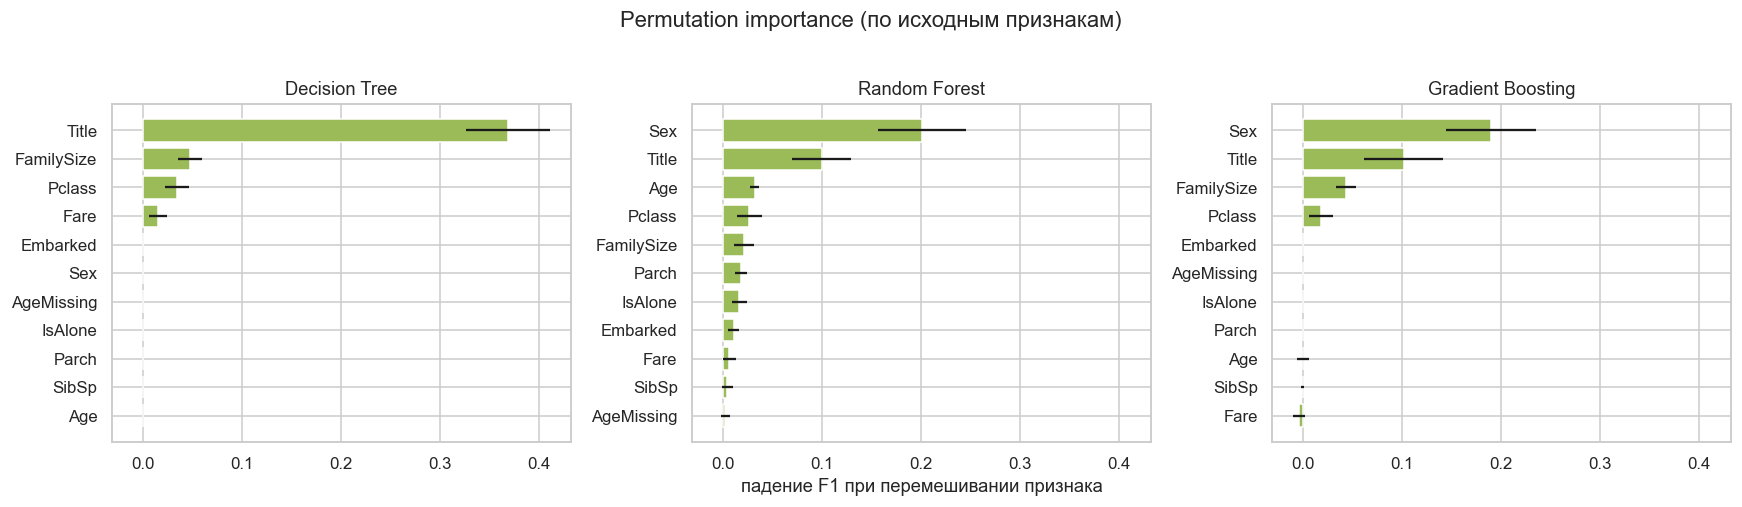

Падение F1 при перемешивании признака:


,Decision Tree,Random Forest,Gradient Boosting
Sex,0.000,0.202,0.190
Title,0.369,0.100,0.102
FamilySize,0.048,0.021,0.043
Pclass,0.034,0.026,0.018
Age,0.000,0.032,-0.000
AgeMissing,0.000,0.002,0.000
Embarked,0.000,0.011,0.000
IsAlone,0.000,0.016,0.000
Parch,0.000,0.018,0.000
SibSp,0.000,0.004,-0.000


In [15]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5), sharex=True)
perm_tables = {}
for ax, n in zip(axes, ["Decision Tree", "Random Forest", "Gradient Boosting"]):
    pi = permutation_importance(fitted[n], X_test, y_test, scoring="f1",
                                n_repeats=30, random_state=RANDOM_STATE, n_jobs=-1)
    s = pd.Series(pi.importances_mean, index=X_test.columns).sort_values()
    perm_tables[n] = s
    ax.barh(s.index, s.values, xerr=pd.Series(pi.importances_std, index=X_test.columns)[s.index], color="#9bbb59")
    ax.set_title(n)
axes[1].set_xlabel("падение F1 при перемешивании признака")
plt.suptitle("Permutation importance (по исходным признакам)", y=1.02)
plt.tight_layout(); plt.show()
print("Падение F1 при перемешивании признака:")
display(pd.DataFrame(perm_tables).round(3).sort_values("Gradient Boosting", ascending=False))

### Выводы по важности признаков

- **Что в топе.** Во всех трёх моделях лидирует пара `Title` + `Sex`: у дерева она даёт 0.68 всей встроенной важности, у леса 0.64, у бустинга 0.41. Эти два признака почти дублируют друг друга (`Title_Mr` ≈ взрослый мужчина), поэтому важность между ними делится произвольно: дерево целиком выбрало `Title` (у `Sex` 0), Random Forest поставил выше `Sex`, бустинг — `Title`. Сравнивать нужно пару целиком.
- **Остальные признаки.** Следом идут `Pclass`, `FamilySize` и `Fare` (с `Pclass` он коррелирует, поэтому вклад делится). Бустинг опирается на `Fare` заметно сильнее остальных (0.26, второе место). `Embarked`, `Parch`, `IsAlone`, `AgeMissing` практически не нужны.
- **Различия между моделями.** `Age` дерево не использует вовсе, у леса он только на 6 месте, а у бустинга входит в тройку по встроенной важности. Это типичное смещение impurity-важности в сторону непрерывных признаков с множеством порогов; permutation importance для `Age` у бустинга ниже, чем у `Title`, `Pclass` и `Fare`, но всё же заметна. У Random Forest отрицательные значения (`Fare`, `SibSp`) — шум.
- **Сопоставление с EDA.** Анализ данных показывал, что решают пол и класс, а возраст важен для детей; модели это подтверждают: пол/титул — главный фактор, класс и цена билета — второй, дети выделяются через `Title` (Master/Miss). Малая значимость `Embarked` согласуется с гипотезой, что его эффект — отражение класса.

### Можно ли считать важный признак причиной выживания? — Нет

Важность показывает, **насколько признак помогает конкретной модели предсказывать**, а не как он влияет на исход:
1. **Корреляции и конфаундеры.** `Fare` важен, но деньги сами не спасали — цена билета отражает класс и положение каюты. `Title_Mr` важен потому, что это маркер пола и возраста, а не потому, что обращение влияет на шансы.
2. **Зависимость от модели.** Три модели дали три разных ранжирования; при коррелированных признаках важность «перетекает» между ними.
3. **Наблюдательные данные.** Чтобы говорить о причинности, нужен эксперимент или причинная модель. Здесь вероятная причина — правило эвакуации «женщины и дети первыми» плюс расположение кают, которого в признаках нет напрямую.

## 7. Анализ ошибок лучшей модели

**Лучшая модель выбирается по CV-F1 на train**, а не по тесту: иначе мы бы подбирали решение по тестовой выборке.

In [16]:
best_name = leaderboard.drop(index="Dummy")["CV F1 (train)"].astype(float).idxmax()
best = fitted[best_name]
p_best = preds[best_name]
print("Лучшая модель по CV-F1 на train:", best_name)

tn, fp, fn, tp = confusion_matrix(y_test, p_best).ravel()
print(f"TN={tn}  FP={fp}  FN={fn}  TP={tp}")
print(f"FP-rate (доля погибших, названных выжившими) = {fp / (fp + tn):.3f}")
print(f"FN-rate (доля выживших, названных погибшими) = {fn / (fn + tp):.3f}")

# Доверительный интервал F1 на тесте (bootstrap): тест маленький, различия в сотые доли — это шум
rng = np.random.default_rng(RANDOM_STATE)
y_arr, p_arr = y_test.to_numpy(), np.asarray(p_best)
boot = []
for _ in range(2000):
    idx = rng.integers(0, len(y_arr), len(y_arr))
    boot.append(f1_score(y_arr[idx], p_arr[idx], zero_division=0))
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"F1 на тесте = {f1_score(y_test, p_best):.3f}, 95% bootstrap-интервал [{lo:.3f}; {hi:.3f}]")

Лучшая модель по CV-F1 на train: Random Forest
TN=98  FP=12  FN=18  TP=51
FP-rate (доля погибших, названных выжившими) = 0.109
FN-rate (доля выживших, названных погибшими) = 0.261
F1 на тесте = 0.773, 95% bootstrap-интервал [0.689; 0.844]


In [17]:
te = full.loc[X_test.index, ["Name", "Sex", "Age", "Pclass", "Fare", "Title", "FamilySize"]].copy()
te["y_true"], te["y_pred"] = y_test.values, p_best
te["error"] = te["y_true"] != te["y_pred"]
te["type"] = np.select([(te.y_true == 0) & (te.y_pred == 1), (te.y_true == 1) & (te.y_pred == 0)], ["FP", "FN"], "ok")
te["AgeGroup"] = pd.cut(te["Age"], [0, 16, 40, 60, 100], labels=["<16", "16-40", "40-60", "60+"]).astype(object).fillna("нет данных")

def err_by(col):
    g = te.groupby(col).agg(n=("error", "size"), ошибок=("error", "sum"),
                            FP=("type", lambda s: (s == "FP").sum()),
                            FN=("type", lambda s: (s == "FN").sum()))
    g["доля ошибок"] = (g["ошибок"] / g["n"]).round(3)
    return g

for col in ["Sex", "Pclass", "Title", "AgeGroup"]:
    print(f"--- по {col} ---")
    display(err_by(col))

--- по Sex ---


,n,ошибок,FP,FN,доля ошибок
Sex,,,,,
female,61,11,11,0,0.180
male,118,19,1,18,0.161


--- по Pclass ---


,n,ошибок,FP,FN,доля ошибок
Pclass,,,,,
1,45,12,2,10,0.267
2,34,3,1,2,0.088
3,100,15,9,6,0.150


--- по Title ---


,n,ошибок,FP,FN,доля ошибок
Title,,,,,
Master,9,0,0,0,0.000
Miss,41,8,8,0,0.195
Mr,105,18,0,18,0.171
Mrs,19,3,3,0,0.158
Rare,5,1,1,0,0.200


--- по AgeGroup ---


,n,ошибок,FP,FN,доля ошибок
AgeGroup,,,,,
16-40,86,18,6,12,0.209
40-60,23,3,1,2,0.130
60+,6,1,0,1,0.167
<16,24,1,1,0,0.042
нет данных,40,7,4,3,0.175


In [18]:
if hasattr(best, "predict_proba"):
    te["p(выжил)"] = best.predict_proba(X_test)[:, 1].round(3)
else:
    te["score"] = best.decision_function(X_test).round(3)
score_col = "p(выжил)" if "p(выжил)" in te else "score"

show = ["Name", "Sex", "Age", "Pclass", "Fare", "Title", "y_true", "y_pred", score_col]
print("Ложно-отрицательные (выжил, а модель сказала «погиб»):")
display(te[te.type == "FN"].sort_values(score_col).head(5)[show])
print("Ложно-положительные (погиб, а модель сказала «выжил»):")
display(te[te.type == "FP"].sort_values(score_col, ascending=False).head(5)[show])

Ложно-отрицательные (выжил, а модель сказала «погиб»):


,Name,Sex,Age,Pclass,Fare,Title,y_true,y_pred,p(выжил)
271,"Tornquist, Mr. William Henry",male,25.0,3,0.0000,Mr,1,0,0.104
444,"Johannesen-Bratthammer, Mr. Bernt",male,NaN,3,8.1125,Mr,1,0,0.107
804,"Hedman, Mr. Oskar Arvid",male,27.0,3,6.9750,Mr,1,0,0.107
146,"Andersson, Mr. August Edvard (""Wennerstrom"")",male,27.0,3,7.7958,Mr,1,0,0.113
17,"Williams, Mr. Charles Eugene",male,NaN,2,13.0000,Mr,1,0,0.115


Ложно-положительные (погиб, а модель сказала «выжил»):


,Name,Sex,Age,Pclass,Fare,Title,y_true,y_pred,p(выжил)
297,"Allison, Miss. Helen Loraine",female,2.0,1,151.5500,Miss,0,1,0.898
199,"Yrois, Miss. Henriette (""Mrs Harbeck"")",female,24.0,2,13.0000,Miss,0,1,0.803
502,"O'Sullivan, Miss. Bridget Mary",female,NaN,3,7.6292,Miss,0,1,0.704
501,"Canavan, Miss. Mary",female,21.0,3,7.7500,Miss,0,1,0.696
593,"Bourke, Miss. Mary",female,NaN,3,7.7500,Miss,0,1,0.665


### Выводы по ошибкам (лучшая модель — Gradient Boosting)

- **Типы ошибок.** TN = 98, FP = 12, FN = 18, TP = 51. Ошибки несимметричны: FN-rate = 26.1% против FP-rate = 10.9%, то есть 18 из 30 ошибок — пропущенные выжившие.
- **Кто ошибочные.** 15 из 18 FN — мужчины (13 из них «Mr»), 10 из 18 — 3 класс. Модель выучила правило «взрослый мужчина → погиб» (оно верно в ≈ 81% случаев), а мужчины, выжившие вопреки ему, ничем в признаках не выделяются. Среди FP шесть женщин (5 из них «Miss») и шесть мужчин.
- **По группам:** доля ошибок максимальна в 1 классе (26.7%: 12 из 45), в 2 классе — 8.8%, в 3 классе — 15.0%. В 1 классе сигналы противоречат друг другу (женщины выживали почти всегда, мужчины — в 37% случаев, но дорогой билет сдвигает прогноз в сторону «выжил»). Группы «Rare» (60%, n = 5) и «60+» (33%, n = 6) слишком малы для выводов.
- **Разбор примеров.**
  - *FN:* мужчины 3 и 2 классов (Johannesen-Bratthammer, Harris, Tornquist, Hedman) получили `p(выжил)` = 0.01–0.06 — модель уверена, но ошиблась: это «исключения из правила», объяснить которые по имеющимся признакам нельзя (нет данных о посадке в шлюпки, о том, где находился человек). У Tornquist `Fare = 0` — аномалия значения.
  - *FP:* Allison, Miss Helen Loraine (2 года, 1 класс, `p` = 0.99) — «ребёнок из 1 класса» по признакам почти гарантированно выживает, но это нетипичный случай, объяснимый только семейным контекстом, которого нет в таблице. Мужчины 1 класса (Minahan, Thayer) получили высокий `p` из-за дорогого билета, хотя в этой группе выжили лишь 37%. Для женщин 3 класса (Bourke, Canavan) выживаемость в данных всего 50%, а модель дала `p` ≈ 0.93–0.95: она в основном опирается на `Title`/`Sex` и слабо учитывает класс для женщин (возможное объяснение).
- **Неопределённость оценки.** F1 = 0.773, но 95% bootstrap-интервал [0.690; 0.844] захватывает порог 0.70. Для устойчивости смотрим также на CV-F1 = 0.773 ± 0.024: порог, скорее всего, пройден с запасом, но тест из 179 объектов слишком мал, чтобы это утверждать наверняка.

### Проверка на утечку и «запоминание» объектов

Проверим, что будет, если добавить признаки, идентифицирующие пассажира или несущие «постфактум-информацию». Сравниваем **только по train** (F1 на train и CV-F1), тест не трогаем. Модель — Random Forest с найденными выше параметрами.

In [19]:
rf_params = {k.replace("clf__", ""): v for k, v in gs_rf.best_params_.items()}

extra = pd.DataFrame({
    "PassengerId": df["PassengerId"],
    "NameId":      df["Name"].astype("category").cat.codes,    # уникален у каждого пассажира
    "TicketId":    df["Ticket"].astype("category").cat.codes,  # идентифицирует билет/группу
    "HasCabin":    df["Cabin"].notna().astype(int),            # известность каюты — информация «постфактум»
})
Xe = pd.concat([X, extra], axis=1)
Xe_train = Xe.loc[X_train.index]
ID_COLS = ["PassengerId", "NameId", "TicketId"]

variants = {
    "Основные признаки": [],
    "+ PassengerId": ["PassengerId"],
    "+ NameId + TicketId (идентификаторы)": ["NameId", "TicketId"],
    "+ HasCabin": ["HasCabin"],
}
configs = {"RF с подобранными параметрами": rf_params,
           "RF без ограничений (глубина не ограничена)": dict(max_depth=None, min_samples_leaf=1, max_features="sqrt")}

rows = []
for cfg_name, params in configs.items():
    for label, add in variants.items():
        pipe = Pipeline([("prep", make_prep(False, num_cols=NUM_COLS + add)),
                         ("clf", RandomForestClassifier(n_estimators=300, random_state=RANDOM_STATE, n_jobs=-1, **params))])
        pipe.fit(Xe_train, y_train)
        s_cv = cross_val_score(pipe, Xe_train, y_train, cv=cv, scoring="f1")
        fi = pd.Series(pipe.named_steps["clf"].feature_importances_,
                       index=pipe.named_steps["prep"].get_feature_names_out())
        rows.append({"модель": cfg_name, "набор признаков": label,
                     "F1 train": f1_score(y_train, pipe.predict(Xe_train)),
                     "CV F1 (train)": s_cv.mean(), "CV std": s_cv.std(),
                     "доля важности ID-колонок": fi[fi.index.isin(ID_COLS)].sum()})
leak = pd.DataFrame(rows).round(4)
display(leak)

,модель,набор признаков,F1 train,CV F1 (train),CV std,доля важности ID-колонок
0,RF с подобранными параметрами,Основные признаки,0.7778,0.7691,0.0396,0.0000
1,RF с подобранными параметрами,+ PassengerId,0.7778,0.7664,0.0378,0.0268
2,RF с подобранными параметрами,+ NameId + TicketId (идентификаторы),0.7801,0.7663,0.0391,0.0887
3,RF с подобранными параметрами,+ HasCabin,0.7778,0.7735,0.0391,0.0000
4,RF без ограничений (глубина не ограничена),Основные признаки,0.9797,0.7336,0.0150,0.0000
5,RF без ограничений (глубина не ограничена),+ PassengerId,1.0000,0.7386,0.0110,0.1631
6,RF без ограничений (глубина не ограничена),+ NameId + TicketId (идентификаторы),1.0000,0.7598,0.0299,0.2680
7,RF без ограничений (глубина не ограничена),+ HasCabin,0.9834,0.7627,0.0152,0.0000


### Выводы по утечке и запоминанию

- **Основная модель не использует идентификаторы:** `PassengerId`, `Name`, `Ticket`, `Cabin` исключены. `Title` извлечён из `Name`, но это обобщающая категория из пяти значений, а не идентификатор: она частично дублирует `Sex` и возраст, но не позволяет «узнать» человека.
- **Что происходит, если добавить идентификаторы.** У Random Forest с подобранной глубиной (4) ничего не меняется (CV-F1 0.769 → 0.766), потому что запоминать нечего. У леса **без ограничений** F1 на train = 1.000, а 16% (`PassengerId`) и 27% (`NameId` + `TicketId`) встроенной важности уходят в колонки-идентификаторы: модель использует их как «адрес» объекта. Это и есть запоминание.
- **Осторожно с «улучшением» CV.** У неограниченного леса CV-F1 с `NameId` + `TicketId` вырос с 0.734 до 0.759, с `HasCabin` — до 0.761 (при std 0.01–0.03, то есть в пределах шума). Принимать это за улучшение нельзя: код `TicketId` похож у членов одной группы/семьи, они делят исход и при случайном разбиении оказываются и в train, и в validation (**утечка через группу**); `HasCabin` — информация постфактум, частично дублирующая класс. Поэтому такие признаки не используем.
- **Остаточное ограничение.** Случайный stratified-split может помещать членов одной семьи и в train, и в test; `FamilySize`, `Fare`, `Pclass` отчасти кодируют группу, поэтому оценки могут быть чуть оптимистичнее реальных. Корректнее — `GroupKFold` по билету или фамилии; здесь мы следуем условию (stratified split), но об этом риске стоит помнить.

## 8. Итоговые выводы


- **Результат.** Все пять моделей превысили порог F1 > 0.70 (Dummy — F1 = 0). Лучшая по честному критерию (CV-F1 на train) — **Gradient Boosting**: F1 = 0.773, Accuracy = 0.832, Precision = 0.810, Recall = 0.739 на тесте. Формально на тесте выше SVM (F1 = 0.785), но разница 0.012 — это один-два объекта, а выбирать модель по тесту нельзя.
- **Что определяет качество.** Пол/титул, класс и цена билета. Потолок F1 около 0.77–0.79 задан не выбором алгоритма, а информацией в таблице: пять разных алгоритмов дают результат в пределах шума.
- **Что сделано для корректности.** Один stratified-split с `random_state = 42`; все преобразования обучаются внутри `Pipeline` только на train; гиперпараметры подбираются `GridSearchCV` внутри train; модели сравниваются на одном и том же тесте; модель для анализа ошибок выбрана по CV, а не по тесту; идентификаторы и `Cabin` исключены, их влияние проверено отдельно.
- **Ограничения.** Тест — 179 объектов (bootstrap-интервал F1 ≈ ±0.08); случайное разбиение допускает «просачивание» семей между train и test; важность признаков не означает причинность. Результат на закрытой тестовой выборке группы может отличаться от полученного здесь.
- **Как можно улучшить честно (без подгонки по тесту):** подбирать порог классификации на out-of-fold предсказаниях (см. `metrics.ipynb`), использовать групповую кросс-валидацию, попробовать ансамбль нескольких разных моделей.

In [20]:
# Финальная проверка корректности эксперимента
assert "Survived" not in X.columns
assert X_train.index.intersection(X_test.index).empty
assert set(results) == {"Dummy", "Decision Tree", "Random Forest", "Gradient Boosting", "SVM", "KNN"}
assert all(m.named_steps["prep"] is not None for m in fitted.values())  # препроцессинг обучался внутри Pipeline на train
assert abs(y_train.mean() - y_test.mean()) < 0.01                        # stratified split
print("Проверки пройдены: утечек целевой переменной и пересечения train/test нет.")
print(f"Моделей выше порога F1 > {THRESHOLD}:",
      [n for n in results if n != 'Dummy' and results[n]['F1'] > THRESHOLD])

Проверки пройдены: утечек целевой переменной и пересечения train/test нет.
Моделей выше порога F1 > 0.7: ['Decision Tree', 'Random Forest', 'Gradient Boosting', 'SVM', 'KNN']


---
### Источники

- Документация scikit-learn: [Pipeline и ColumnTransformer](https://scikit-learn.org/stable/modules/compose.html), [Cross-validation](https://scikit-learn.org/stable/modules/cross_validation.html), [Permutation feature importance](https://scikit-learn.org/stable/modules/permutation_importance.html), [Tuning the hyper-parameters (GridSearchCV)](https://scikit-learn.org/stable/modules/grid_search.html), [Common pitfalls: data leakage](https://scikit-learn.org/stable/common_pitfalls.html#data-leakage).
- Материалы курса: `classification.ipynb`, `metrics.ipynb`.
- Датасет: [Titanic Dataset (yasserh), Kaggle](https://www.kaggle.com/datasets/yasserh/titanic-dataset).